In [200]:
# 1. Environment and configuration

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/prices.csv")

TARGET_COMMODITY = "Rice (low quality)"
TARGET_UNIT = "KG"
TARGET_PRICE_TYPE = "Retail"
TARGET_CURRENCY = "MMK"
PAKOKKU_ID = 1664

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. "
        "Check the notebook working directory and DATA_PATH."
    )

In [201]:
df = pd.read_csv(DATA_PATH)
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

required_columns = {
    "date", "commodity", "market_id", "market",
    "unit", "pricetype", "currency", "price"
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Required columns are missing: {sorted(missing_columns)}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")

text_columns = df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df[column] = df[column].str.strip()

rice_df = df[
    (df["commodity"] == TARGET_COMMODITY)
    & (df["unit"] == TARGET_UNIT)
    & (df["pricetype"] == TARGET_PRICE_TYPE)
    & (df["currency"] == TARGET_CURRENCY)
].dropna(subset=["date", "price"]).copy()

rice_df["month"] = rice_df["date"].dt.to_period("M")

monthly_rice = (
    rice_df.groupby(["market_id", "market", "month"])
    .agg(
        monthly_price=("price", "mean"),
        observation_count=("price", "count")
    )
    .reset_index()
    .sort_values(["market_id", "month"])
)

print("Monthly market-price rows:", len(monthly_rice))
print("Markets:", monthly_rice["market_id"].nunique())


df_pakokku = (
    monthly_rice[monthly_rice["market_id"] == PAKOKKU_ID]
    .sort_values("month")
    .set_index("month")
    .copy()
)

if df_pakokku.empty:
    raise ValueError(
        f"No rice observations found for market ID {PAKOKKU_ID}."
    )

# Explicitly construct the complete monthly timeline
full_month_index = pd.period_range(
    start=df_pakokku.index.min(),
    end=df_pakokku.index.max(),
    freq="M"
)

df_pakokku = df_pakokku.reindex(full_month_index)
df_pakokku.index.name = "month"

print("Total months:", len(df_pakokku))
print("Missing prices:", df_pakokku["monthly_price"].isna().sum())

display(
    df_pakokku[df_pakokku["monthly_price"].isna()]
)





Monthly market-price rows: 10231
Markets: 298
Total months: 153
Missing prices: 7


,market_id,market,monthly_price,observation_count
month,,,,
2015-05,NaN,NaN,NaN,NaN
2015-06,NaN,NaN,NaN,NaN
2015-07,NaN,NaN,NaN,NaN
2019-05,NaN,NaN,NaN,NaN
2019-06,NaN,NaN,NaN,NaN
2020-02,NaN,NaN,NaN,NaN
2025-01,NaN,NaN,NaN,NaN


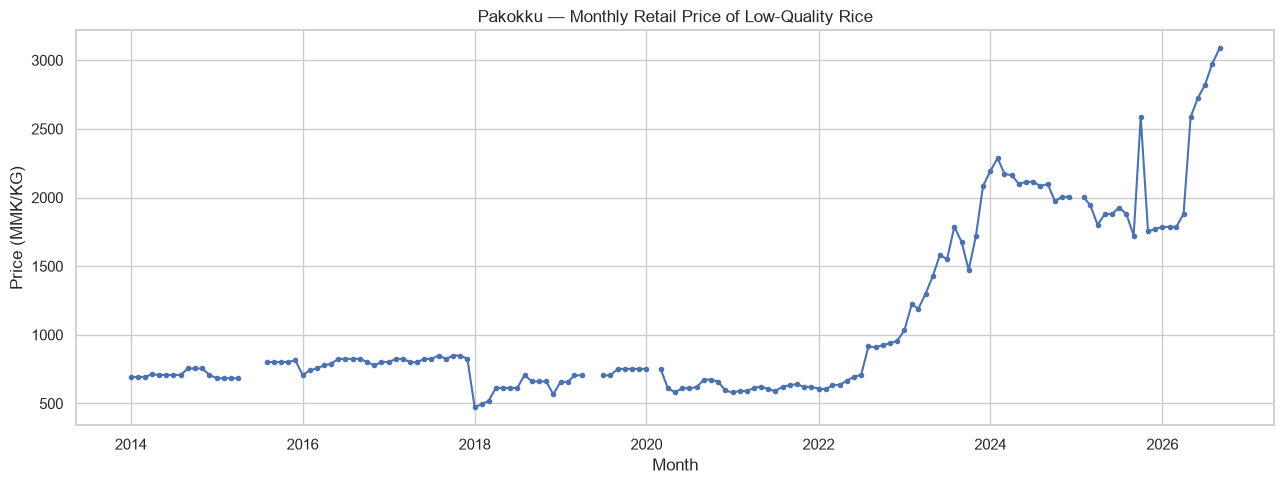

In [202]:
plt.figure(figsize=(13, 5))


plt.plot(
    df_pakokku.index.to_timestamp(),
    df_pakokku["monthly_price"],
    markersize=3,
    linewidth=1.5,
    marker="o"
)

plt.title("Pakokku — Monthly Retail Price of Low-Quality Rice")
plt.xlabel("Month")
plt.ylabel("Price (MMK/KG)")
plt.tight_layout()
plt.show()



In [203]:
df_pakokku["rolling_mean_3"] = (
    df_pakokku["monthly_price"]
    .rolling(window=3, min_periods=3)
    .mean()
)

df_pakokku["rolling_mean_12"] = (
    df_pakokku["monthly_price"]
    .rolling(window=12, min_periods=12)
    .mean()
)

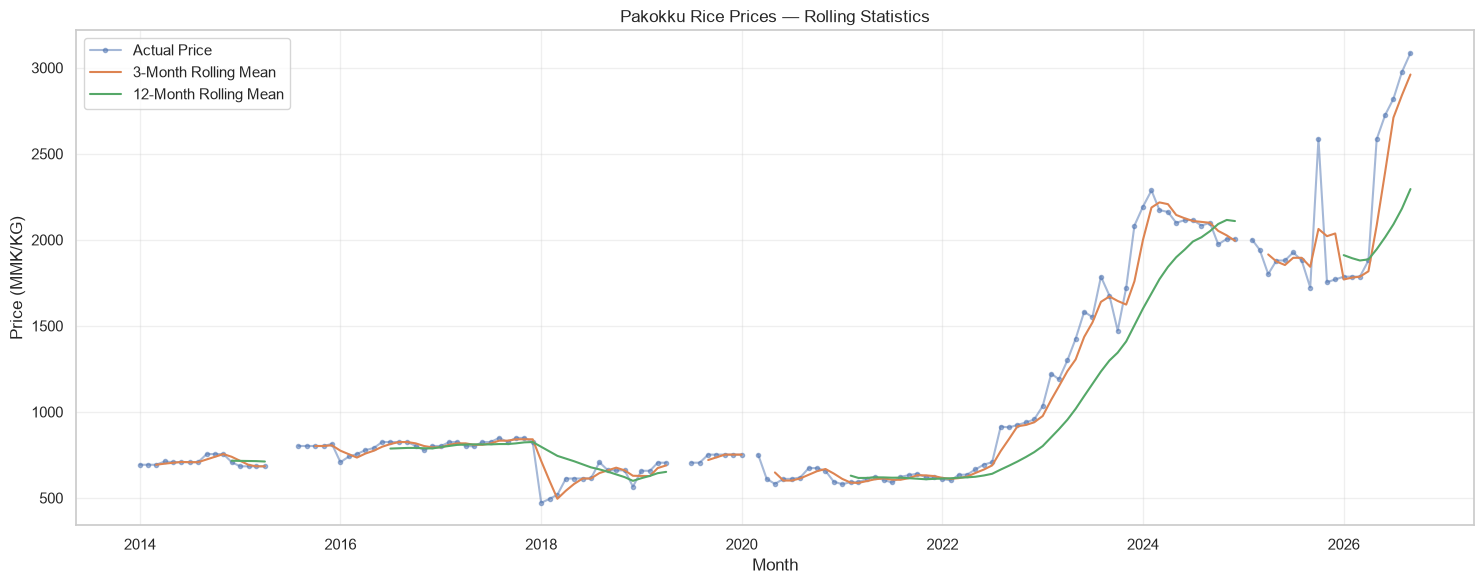

In [204]:
plt.figure(figsize=(15, 6))

plt.plot(
    df_pakokku.index.to_timestamp(),
    df_pakokku["monthly_price"],
    label="Actual Price",
    alpha=0.5,
    marker="o",
    markersize=3
)

plt.plot(
    df_pakokku.index.to_timestamp(),
    df_pakokku["rolling_mean_3"],
    label="3-Month Rolling Mean",
)

plt.plot(
    df_pakokku.index.to_timestamp(),
    df_pakokku["rolling_mean_12"],
    label="12-Month Rolling Mean"
)

plt.title("Pakokku Rice Prices — Rolling Statistics")
plt.xlabel("Month")
plt.ylabel("Price (MMK/KG)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [205]:
display(
    df_pakokku[
        [
            "monthly_price",
            "rolling_mean_3",
            "rolling_mean_12"
        ]
    ].head(153)
)

,monthly_price,rolling_mean_3,rolling_mean_12
month,,,
2014-01,693.0,NaN,NaN
2014-02,693.0,NaN,NaN
2014-03,693.0,693.000000,NaN
2014-04,712.0,699.333333,NaN
2014-05,708.0,704.333333,NaN
...,...,...,...
2026-05,2585.0,2083.666667,1945.333333
2026-06,2726.0,2397.000000,2015.833333
2026-07,2820.0,2710.333333,2090.250000


In [206]:
print(
    df_pakokku[
        [
            "monthly_price",
            "rolling_mean_3",
            "rolling_mean_12"
        ]
    ].to_markdown()
)

| month   |   monthly_price |   rolling_mean_3 |   rolling_mean_12 |
|:--------|----------------:|-----------------:|------------------:|
| 2014-01 |          693    |          nan     |           nan     |
| 2014-02 |          693    |          nan     |           nan     |
| 2014-03 |          693    |          693     |           nan     |
| 2014-04 |          712    |          699.333 |           nan     |
| 2014-05 |          708    |          704.333 |           nan     |
| 2014-06 |          708    |          709.333 |           nan     |
| 2014-07 |          708    |          708     |           nan     |
| 2014-08 |          708    |          708     |           nan     |
| 2014-09 |          755    |          723.667 |           nan     |
| 2014-10 |          755    |          739.333 |           nan     |
| 2014-11 |          755    |          755     |           nan     |
| 2014-12 |          708    |          739.333 |           716.333 |
| 2015-01 |          684    |     

B. The most interesting price movements

Some observations deserve further investigation:

Period	                Observation
Early 2018	            Price drops from 825 to 472
2022	                Price rises substantially from mid-year
2023–2024	            Strong upward price movement
Late 2024–2025	        Prices decline from their previous levels
October 2025	        Price jumps to 2,587
May–September 2026	    Another substantial increase

Notice something important: our series is not simply following one smooth upward trend.

It contains sudden changes, relatively stable periods, declines, and strong increases.

That makes forecasting interesting.

In [207]:
df_pakokku["monthly_change_pct"] = (
    df_pakokku["monthly_price"]
    .pct_change(fill_method=None) * 100
)

display(
    df_pakokku[
        df_pakokku["monthly_change_pct"].abs() > 20
    ][["monthly_price", "monthly_change_pct"]]
)

,monthly_price,monthly_change_pct
month,,
2018-01,472.0,-42.787879
2022-08,915.0,29.237288
2023-12,2083.0,20.893790
2025-10,2587.0,50.145096
2025-11,1754.0,-32.199459
2026-05,2585.0,37.500000


<Figure size 1200x500 with 0 Axes>

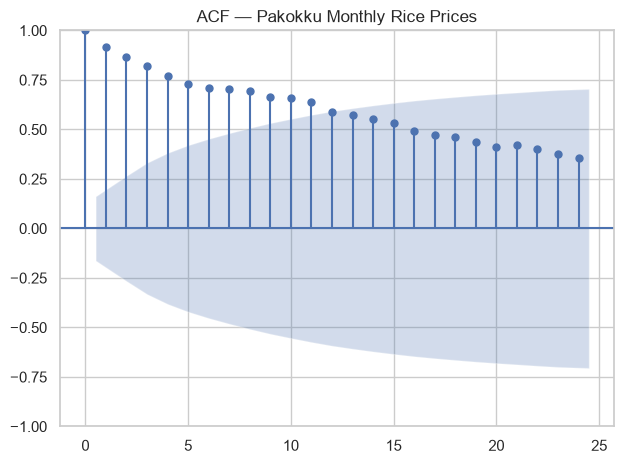

In [208]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 5))

plot_acf(
    df_pakokku["monthly_price"],
    lags=24,
    missing="conservative"
)

plt.title("ACF — Pakokku Monthly Rice Prices")
plt.tight_layout()
plt.show()

In [209]:
unusual_months = [
    "2018-01",
    "2022-08",
    "2023-12",
    "2025-10",
    "2025-11",
    "2026-05",
]

unusual_records = rice_df[
    (rice_df["market_id"] == PAKOKKU_ID)
    & (rice_df["month"].astype(str).isin(unusual_months))
].sort_values("date")

display(
    unusual_records[
        [
            "date",
            "commodity",
            "market",
            "unit",
            "pricetype",
            "currency",
            "price",
        ]
    ]
)

,date,commodity,market,unit,pricetype,currency,price
16926,2018-01-15,Rice (low quality),Pakokku Myo Ma Market,KG,Retail,MMK,472.0
33817,2022-08-15,Rice (low quality),Pakokku Myo Ma Market,KG,Retail,MMK,915.0
44694,2023-12-15,Rice (low quality),Pakokku Myo Ma Market,KG,Retail,MMK,2083.0
55521,2025-10-15,Rice (low quality),Pakokku Myo Ma Market,KG,Retail,MMK,2587.0
55944,2025-11-15,Rice (low quality),Pakokku Myo Ma Market,KG,Retail,MMK,1754.0
59036,2026-05-15,Rice (low quality),Pakokku Myo Ma Market,KG,Retail,MMK,2585.0


In [210]:
display(
    df_pakokku.loc[
        pd.PeriodIndex(unusual_months, freq="M"),
        ["monthly_price", "observation_count"]
    ]
)

,monthly_price,observation_count
month,,
2018-01,472.0,1.0
2022-08,915.0,1.0
2023-12,2083.0,1.0
2025-10,2587.0,1.0
2025-11,1754.0,1.0
2026-05,2585.0,1.0


In [211]:
TAUNGGYI_ID = 1019
HLAINGBWE_ID = 3280
KHANTAR_ID = 3302
KALAW_ID = 8028

combined_prices = monthly_rice[
    monthly_rice["market_id"].isin([PAKOKKU_ID, TAUNGGYI_ID, HLAINGBWE_ID, KHANTAR_ID, KALAW_ID])
].copy()

market_comparison = (
    combined_prices
    .pivot(index="month", columns="market", values="monthly_price")
    .sort_index()
)

market_returns = market_comparison.pct_change(fill_method=None) * 100

display(market_returns.loc["2024":"2026"])

market_returns = market_comparison.pct_change(
    fill_method=None
) * 100

display(market_returns.loc["2024":"2026"])

market,Hlaing Bwe Myo Ma market,KalawMyoma,Kanthar,Pakokku Myo Ma Market,Taunggyi
month,,,,,
2024-01,5.452128,0.602168,0.000000,5.280845,0.000000
2024-02,12.610340,0.000000,-0.882786,4.286366,-7.407407
2024-03,13.157895,1.875499,4.057397,-4.984696,0.000000
2024-04,10.440376,2.467685,5.563481,-0.506213,NaN
2024-05,5.286738,1.185015,-0.495495,-2.913969,NaN
2024-06,9.982553,-1.174537,2.111363,0.746070,-2.099014
2024-07,6.825454,-1.793257,0.015960,0.016078,5.393222
2024-08,-5.976096,-1.206695,0.000000,-1.513002,2.040816
2024-09,0.462250,2.442868,0.000000,0.768123,10.000000


market,Hlaing Bwe Myo Ma market,KalawMyoma,Kanthar,Pakokku Myo Ma Market,Taunggyi
month,,,,,
2024-01,5.452128,0.602168,0.000000,5.280845,0.000000
2024-02,12.610340,0.000000,-0.882786,4.286366,-7.407407
2024-03,13.157895,1.875499,4.057397,-4.984696,0.000000
2024-04,10.440376,2.467685,5.563481,-0.506213,NaN
2024-05,5.286738,1.185015,-0.495495,-2.913969,NaN
2024-06,9.982553,-1.174537,2.111363,0.746070,-2.099014
2024-07,6.825454,-1.793257,0.015960,0.016078,5.393222
2024-08,-5.976096,-1.206695,0.000000,-1.513002,2.040816
2024-09,0.462250,2.442868,0.000000,0.768123,10.000000


In [212]:
# Five markets selected for comparison
markets = [
    "Hlaing Bwe Myo Ma market",
    "KalawMyoma",
    "Kanthar",
    "Pakokku Myo Ma Market",
    "Taunggyi"
]

# Keep only the selected markets and required columns
five_market_rows = monthly_rice.loc[
    monthly_rice["market"].isin(markets),
    ["month", "market", "monthly_price"]
].copy()

# Check for duplicate market-month combinations
duplicates = five_market_rows[
    five_market_rows.duplicated(
        subset=["month", "market"],
        keep=False
    )
]

display(duplicates)

,month,market,monthly_price


In [213]:
# Convert rows into a market-by-month matrix
market_prices = five_market_rows.pivot(
    index="month",
    columns="market",
    values="monthly_price"
)

# Create a complete monthly calendar
full_months = pd.period_range(
    start=market_prices.index.min(),
    end=market_prices.index.max(),
    freq="M"
)

# Restore missing calendar months without filling their prices
market_prices = market_prices.reindex(
    index=full_months,
    columns=markets
)


print(market_prices.to_markdown())

|         |   Hlaing Bwe Myo Ma market |   KalawMyoma |   Kanthar |   Pakokku Myo Ma Market |   Taunggyi |
|:--------|---------------------------:|-------------:|----------:|------------------------:|-----------:|
| 2008-01 |                     nan    |       nan    |    nan    |                  nan    |     320    |
| 2008-02 |                     nan    |       nan    |    nan    |                  nan    |     300    |
| 2008-03 |                     nan    |       nan    |    nan    |                  nan    |     nan    |
| 2008-04 |                     nan    |       nan    |    nan    |                  nan    |     nan    |
| 2008-05 |                     nan    |       nan    |    nan    |                  nan    |     400    |
| 2008-06 |                     nan    |       nan    |    nan    |                  nan    |     nan    |
| 2008-07 |                     nan    |       nan    |    nan    |                  nan    |     360    |
| 2008-08 |                     nan  

In [214]:
# Calculate percentage changes between consecutive calendar months
market_returns = (
    market_prices
    .pct_change(fill_method=None)
    .mul(100)
)

print(market_returns.to_markdown())

|         |   Hlaing Bwe Myo Ma market |   KalawMyoma |     Kanthar |   Pakokku Myo Ma Market |     Taunggyi |
|:--------|---------------------------:|-------------:|------------:|------------------------:|-------------:|
| 2008-01 |                nan         |   nan        | nan         |             nan         | nan          |
| 2008-02 |                nan         |   nan        | nan         |             nan         |  -6.25       |
| 2008-03 |                nan         |   nan        | nan         |             nan         | nan          |
| 2008-04 |                nan         |   nan        | nan         |             nan         | nan          |
| 2008-05 |                nan         |   nan        | nan         |             nan         | nan          |
| 2008-06 |                nan         |   nan        | nan         |             nan         | nan          |
| 2008-07 |                nan         |   nan        | nan         |             nan         | nan          |
|

In [215]:


diagnostics = pd.DataFrame(index=markets)

# 1. Number of observed monthly prices
diagnostics["valid_months"] = market_prices.count()

# 2. Number of genuine consecutive-month changes
diagnostics["valid_pairs"] = market_returns.count()

# 3. Percentage of changes equal to zero
diagnostics["zero_change_rate_pct"] = (
    market_returns.eq(0).where(market_returns.notna()).mean() * 100
)

# 4. Typical absolute monthly change
diagnostics["median_abs_change_pct"] = (
    market_returns.abs().median()
)

# 5. Large absolute monthly changes
diagnostics["p90_abs_change_pct"] = (
    market_returns.abs().quantile(0.90)
)

# 6. Largest absolute monthly change
diagnostics["max_abs_change_pct"] = (
    market_returns.abs().max()
)

display(diagnostics.round(2))

,valid_months,valid_pairs,zero_change_rate_pct,median_abs_change_pct,p90_abs_change_pct,max_abs_change_pct
Hlaing Bwe Myo Ma market,77,75,8.0,7.13,22.45,37.84
KalawMyoma,48,46,8.695652,4.35,22.12,94.44
Kanthar,77,75,38.666667,0.29,11.50,32.57
Pakokku Myo Ma Market,146,141,25.531915,2.50,13.02,50.15
Taunggyi,108,91,30.769231,5.88,22.22,66.67
